# 02 — Odd integer increments: staircase and absorption boundary

**Goal.** Reproduce Figures **04** and **05** of the English LaTeX report, including the common inexactness threshold and the dependence of the absorption boundary on the bits of $c$.

**Sources.** *artigo_ulp.pdf*, Section 4 (particularly its $c=101$ table); *relatorio_ulp.pdf*, Section 5; supplied `grafico_x10_impares.html`.

In [1]:
from pathlib import Path
import sys, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, LogNorm
from matplotlib.patches import Patch
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / 'src' / 'ulp_lab.py').exists():
    ROOT = ROOT.parent
if not (ROOT / 'src' / 'ulp_lab.py').exists():
    raise FileNotFoundError('Open Jupyter in the extracted ULP_Jupyter_Reproducibility folder.')
sys.path.insert(0, str(ROOT / 'src'))
from ulp_lab import (evaluate, ulp, v2, floor_log2, theory, possible_results,
                     sample_binade, valid_same_binade_mask, generate_cases, validate_one)
FIG = ROOT / 'figures'; FIG.mkdir(exist_ok=True)
RES = ROOT / 'results'; RES.mkdir(exist_ok=True)
BLUE='#2367A6'; ORANGE='#DD8A29'; GREEN='#2C977F'; RED='#B85751'; PURPLE='#8572AB'
plt.rcParams.update({'font.size':10,'figure.dpi':110,'savefig.dpi':190,
                     'axes.grid':True,'grid.alpha':.20,
                     'axes.spines.top':False,'axes.spines.right':False})
print('Working directory:', ROOT)
print('NumPy:', np.__version__)

Working directory: /mnt/data/ULP_Jupyter_Reproducibility
NumPy: 2.3.5


## Theoretical predictions

For positive odd integers $c$ (exactly represented), $\nu(c)=0$ and

$$x_1=2^{53/10}\approx39.3966,\quad x_2=2^{(54+\lfloor\log_2 c\rfloor)/10},\quad L=\lfloor\log_2 c\rfloor+1.$$

The first inexact binade has ULP 2, so the odd increment falls at a tie and yields $c-1$ or $c+1$. Later binades produce one rounded multiple of the local ULP, and eventually zero.

In [2]:
cs=[1,3,5,11,21,101,173,1001]
rows=[{'c':c,'nu':theory(c).nu,'L':theory(c).L,
       'x1':theory(c).x1,'x2':theory(c).x2} for c in cs]
tab=pd.DataFrame(rows)
display(tab.round(4));tab.to_csv(RES/'02_odd_thresholds.csv',index=False)
assert len(set(round(theory(c).x1,12) for c in cs))==1
assert theory(101).x2 == 64.0

,c,nu,L,x1,x2
0,1,0,1,39.3966,42.2243
1,3,0,2,39.3966,45.2548
2,5,0,3,39.3966,48.5029
3,11,0,4,39.3966,51.9842
4,21,0,5,39.3966,55.7152
5,101,0,7,39.3966,64.0000
6,173,0,8,39.3966,68.5935
7,1001,0,10,39.3966,78.7932


## Figure 04 — the staircase for $c=3,5,11,21$

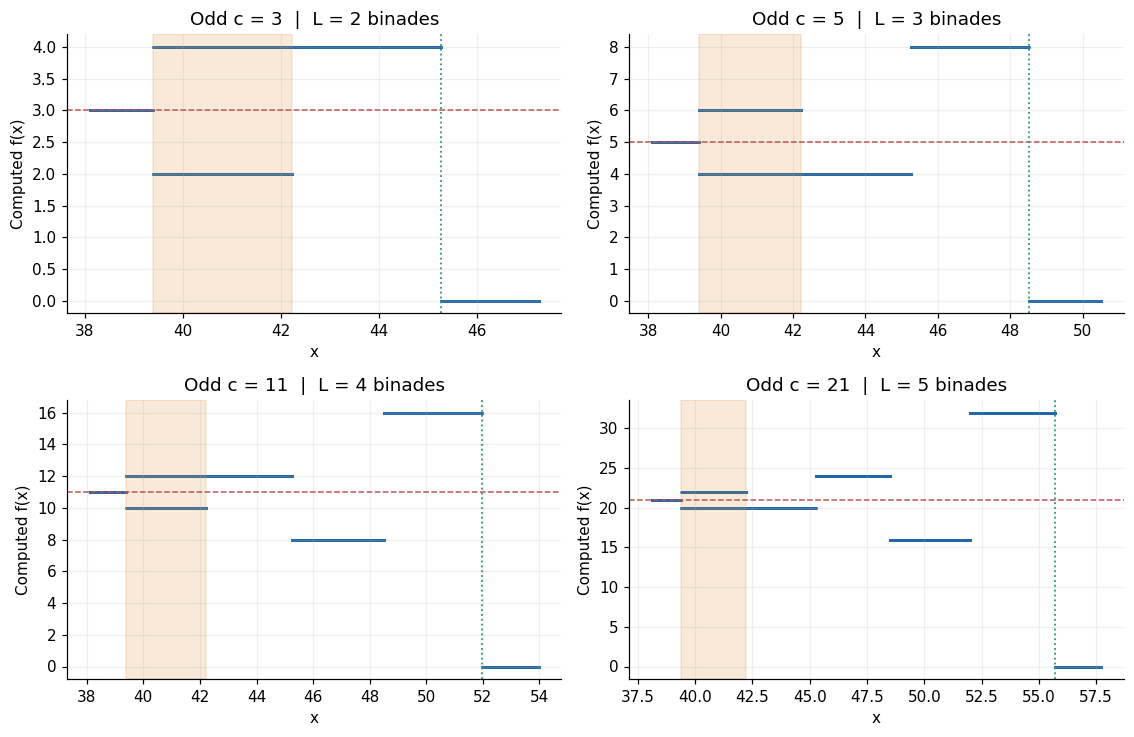

In [3]:
fig,axs=plt.subplots(2,2,figsize=(10.5,6.8))
for ax,c in zip(axs.ravel(),[3,5,11,21]):
    t=theory(c);x=np.linspace(t.x1-1.3,t.x2+2,13500)
    r,_=evaluate(x,c)
    ax.scatter(x,r,color=BLUE,s=.55,rasterized=True)
    ax.axhline(c,color=RED,ls='--',lw=1,label='Exact c')
    ax.axvspan(t.x1,2**(54/10),color=ORANGE,alpha=.18,label='Tie binade')
    ax.axvline(t.x2,color=GREEN,ls=':',lw=1.2,label='Absorption boundary')
    ax.set(xlabel='x',ylabel='Computed f(x)',title=f'Odd c = {c}  |  L = {t.L} binades')
fig.tight_layout()
fig.savefig(FIG / '04_odd_integer_curves.png', bbox_inches='tight', facecolor='white'); plt.show(); plt.close(fig)

## Worked example: the seven inexact binades of $c=101$

`possible_results` gives a set of permitted values. Only the first inexact binade has two outcomes (the parity tie). We compute a second independent sample to check each row.

In [4]:
c=101; t=theory(c);rng=np.random.default_rng(2026)
rows=[]
for E in range(t.E1-1,t.E2+3):
    x,r,y,Er=sample_binade(c,E,count=3500,rng=rng)
    valid, crossing, ysmall=valid_same_binade_mask(y,c,E)
    observed=sorted(set(np.unique(r[(Er==E)&valid]).tolist()))
    expected=sorted(possible_results(c,E))
    assert set(observed).issubset(expected)
    u=math.ldexp(1.0,E-52)
    rows.append({'E':E,'x_min':2**(E/10),'ULP':u,'c/ULP':c/u,
                 'predicted f':str(expected),'observed f':str(observed)})
df101=pd.DataFrame(rows)
display(df101)
df101.to_csv(RES/'02_c101_by_binade.csv',index=False)

,E,x_min,ULP,c/ULP,predicted f,observed f
0,52,36.758347,1.0,101.000000,[101.0],[101.0]
1,53,39.396621,2.0,50.500000,"[100.0, 102.0]","[100.0, 102.0]"
2,54,42.224253,4.0,25.250000,[100.0],[100.0]
3,55,45.254834,8.0,12.625000,[104.0],[104.0]
4,56,48.502930,16.0,6.312500,[96.0],[96.0]
5,57,51.984153,32.0,3.156250,[96.0],[96.0]
6,58,55.715236,64.0,1.578125,[128.0],[128.0]
7,59,59.714111,128.0,0.789062,[128.0],[128.0]
8,60,64.000000,256.0,0.394531,[0.0],[0.0]
9,61,68.593502,512.0,0.197266,[0.0],[0.0]


## Figure 05 — relative error for odd $c=1,3,\ldots,255$

White means an exact result. The darkest values indicate full absorption ($|f-c|/c=1$). The green staircase is the predicted boundary $x_2(c)$, and the blue line is the common onset $x_1$.

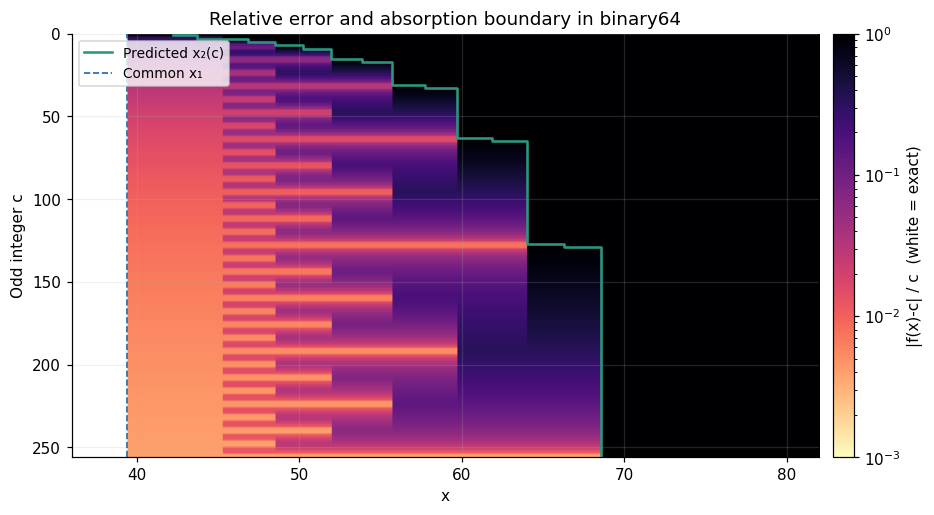

In [5]:
odd_cs=np.arange(1,256,2,dtype=np.float64)
x=np.linspace(36,82,1900)
err=np.empty((len(odd_cs),len(x)))
for i,c in enumerate(odd_cs):
    r,_=evaluate(x,c);err[i]=np.abs(r-c)/c
masked=np.ma.masked_where(err==0,err)
fig,ax=plt.subplots(figsize=(10.5,5.0))
cmap=plt.get_cmap('magma_r').copy();cmap.set_bad('white')
im=ax.imshow(masked,extent=[x.min(),x.max(),odd_cs.max()+1,odd_cs.min()-1],
             aspect='auto',cmap=cmap,norm=LogNorm(vmin=1e-3,vmax=1))
ax.step([theory(c).x2 for c in odd_cs],odd_cs,where='mid',
        color=GREEN,lw=1.7,label='Predicted x₂(c)')
ax.axvline(theory(1).x1,color=BLUE,ls='--',lw=1.1,label='Common x₁')
ax.set(xlabel='x',ylabel='Odd integer c',title='Relative error and absorption boundary in binary64')
fig.colorbar(im,ax=ax,pad=.015,label='|f(x)-c| / c  (white = exact)')
ax.legend(loc='upper left',fontsize=9)
fig.savefig(FIG / '05_odd_integer_heatmap.png', bbox_inches='tight', facecolor='white'); plt.show(); plt.close(fig)

## Conclusion

All exactly represented odd integer increments share the **same onset** in binary64 ($x_1\approx39.40$), but the width is the bit length of the integer: for $c=101$, $L=7$ and the predicted zero regime starts at $x_2=64$. The rounding error can change sign between adjacent binades; the graph need not be monotone.